In [2]:
import pandas as pd
import yfinance as yf

import pandas as pd
import yfinance as yf

# 1. Download historical daily data for Brent Crude Oil (ticker: BZ=F) over the last 3 years
ticker = "BZ=F"
data = yf.download(ticker, start="2025-01-01", end="2026-10-13")

# 2. Inspect the first few rows (notice we care mostly about the 'Close' or 'Adj Close' price)
print(data.tail())

# 3. Check for any missing data gaps (crucial for time series)
data.isnull().sum()

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_57676/1084396911.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2025-01-01", end="2026-10-13")
[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open Volume
Ticker            BZ=F        BZ=F        BZ=F        BZ=F   BZ=F
Date                                                             
2026-10-06  100.580002  101.300003   97.080002  100.260002  43157
2026-10-07  100.199997  102.589996   99.620003  100.970001  47830
2026-10-08  104.279999  105.910004  100.750000  101.129997  47377
2026-10-09  104.720001  105.070000  102.389999  103.900002  28889
2026-10-12  106.650002  107.300003  102.349998  104.639999  34229


Price   Ticker
Close   BZ=F      0
High    BZ=F      0
Low     BZ=F      0
Open    BZ=F      0
Volume  BZ=F      0
dtype: int64

## Log Return and Volatility
### Convert prices into log returns 
Raw prices are non-stationary meaning their statistical properties (mean and variance) change over time. 
Therefore, prices are converted into log returns as Log returns measure percentage changes symmetrically, handle compounding continuously, and—crucially—transform a trending series into a stationary, mean-reverting series that statistical models can actually process.

### Volatility 
Calculate standard deviation using 30 days data, if too long it will smooth out and miss when the risk occured. 

In [3]:
import numpy as np
# Pull the data from Phase 1
# Use the 'Close' price series (handling multi-index columns if returned by yfinance)
prices = data["Close"]

# 1. Calculate Daily Log Returns
# np.log(P_t / P_t-1)
log_returns = np.log(prices / prices.shift(1))

# Drop the first NaN row generated by the shift
log_returns = log_returns.dropna()

# 2. Calculate 30-Day Rolling Standard Deviation (Annualized Volatility)
# Multiply by sqrt(252) because there are ~252 trading days in a year
rolling_volatility = log_returns.rolling(window=30).std() * np.sqrt(252)

# Inspect the results
print("Sample Log Returns:")
print(log_returns.tail())
print("\nSample Rolling Volatility:")
print(rolling_volatility.tail())

Sample Log Returns:
Ticker          BZ=F
Date                
2026-10-06  0.002588
2026-10-07 -0.003785
2026-10-08  0.039911
2026-10-09  0.004211
2026-10-12  0.018262

Sample Rolling Volatility:
Ticker          BZ=F
Date                
2026-10-06  0.392354
2026-10-07  0.371696
2026-10-08  0.383750
2026-10-09  0.381032
2026-10-12  0.381761


Test if non-stationary 
Using **Augmented Dickey-Fuller** / ADF Test

- **Null Hypothesis (H0)**: The series is non-stationary (it has a unit root).
- **Alternative Hypothesis (H1)**: The series is stationary.
- **Decision Rule**: If the p-value is less than 0.05, we reject the null hypothesis and mathematically prove our data is stationary and ready for forecasting.

In [4]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
import yfinance as yf

# If log_returns comes out as a multi-index dataframe, flatten it to a clean Series:
if isinstance(log_returns, pd.DataFrame):
    log_returns = log_returns.iloc[:, 0]

# 2. Run the Augmented Dickey-Fuller test
adf_result = adfuller(log_returns)

print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

# 3. Decision logic
if adf_result[1] < 0.05:    
    print(
    "\nConclusion: p-value < 0.05. We reject the null hypothesis. The series"
    " is STATIONARY!"
)
else:
    print(
    "\nConclusion: p-value >= 0.05. The series is non-stationary. We need"
    " to difference it again."
)

ADF Statistic: -9.7880
p-value: 0.0000
Critical Values:
   1%: -3.4452
   5%: -2.8681
   10%: -2.5703

Conclusion: p-value < 0.05. We reject the null hypothesis. The series is STATIONARY!


## Build a forecasting model 
ARIMA -> Autoregressive Integrated Moving Average. It is the baseline workhorse model for time-series forecasting.

AR (Autoregressive - p): Uses past values to predict future values (e.g., "how much did yesterday's price drop affect today?").
I (Integrated - d): The number of times the data had to be differenced to make it stationary (which we just proved using log returns and the ADF test).
** in time series, integration means subtracting yesterday's value from today's value -> strip out the trend and left only the rate of change 

MA (Moving Average - q): Uses past forecast errors (shocks or surprises in the market) to smooth out predictions.
** modelling relationship between observation and residual(shock or surpise from an event)- > capture remaining effect of that shock 

Evaluate accuracy with MAE and RMSE 
MAE -> how much is off on average 
RMSE -> penalise larger error heavily 


In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import yfinance as yf

# 2. Split data into Train (80%) and Test (20%) to prevent cheating
train_size = int(len(log_returns) * 0.8)
train_data = log_returns.iloc[:train_size]
test_data = log_returns.iloc[train_size:]

# 3. Fit an ARIMA(1,0,1) model on the training log returns
# p=1, d=0 (already stationary), q=1
model = ARIMA(train_data, order=(1, 0, 1))
model_fitted = model.fit()

# 4. Forecast the exact length of our test set
predictions = model_fitted.forecast(steps=len(test_data))

# 5. Evaluate Error Metrics
mae = mean_absolute_error(test_data, predictions)
rmse = root_mean_squared_error(test_data, predictions)

print(f"Model Training Complete!")
print(f"MAE (Mean Absolute Error): {mae:.6f}")
print(f"RMSE (Root Mean Square Error): {rmse:.6f}")

Model Training Complete!
MAE (Mean Absolute Error): 0.024259
RMSE (Root Mean Square Error): 0.031611


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


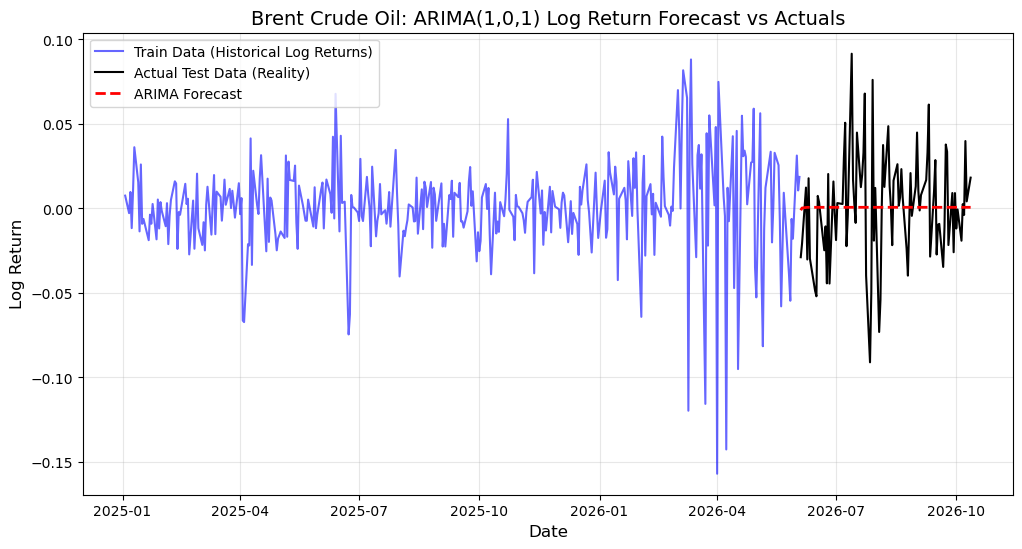

In [6]:
import matplotlib.pyplot as plt

# --- (Run this right after your Phase 4 ARIMA forecasting code) ---

plt.figure(figsize=(12, 6))

# Plot training data
plt.plot(
    train_data.index,
    train_data,
    label="Train Data (Historical Log Returns)",
    color="blue",
    alpha=0.6,
)

# Plot actual test data
plt.plot(
    test_data.index,
    test_data,
    label="Actual Test Data (Reality)",
    color="black",
    linewidth=1.5,
)

# Plot ARIMA model predictions
plt.plot(
    test_data.index,
    predictions,
    label="ARIMA Forecast",
    color="red",
    linestyle="--",
    linewidth=2,
)

plt.title(
    "Brent Crude Oil: ARIMA(1,0,1) Log Return Forecast vs Actuals", fontsize=14
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Log Return", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()